# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Fauzan Tamma Harish Kunfaza | 5054251035 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan:
# pandas, numpy, matplotlib, seaborn
# StandardScaler dari sklearn.preprocessing
# DBSCAN dari sklearn.cluster
# Birch dari sklearn.cluster
# GaussianMixture dari sklearn.mixture
# silhouette_score, davies_bouldin_score, calinski_harabasz_score dari sklearn.metrics

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

In [ ]:
# Muat Mall_Customers.csv ke dalam DataFrame bernama df.
# Jika file tidak ditemukan, periksa lokasi file dan nama file.
# Tampilkan 5 baris pertama, jumlah baris/kolom, tipe data, statistik deskriptif,
# jumlah missing value, dan jumlah baris duplikat.

df = pd.read_csv('Mall_Customers.csv')

print(df.shape)
display(df.head())
df.info()
display(df.describe())


print(df.isnull().sum())
print(,"duplikat: "X.duplicated().sum())

SyntaxError: invalid syntax. Perhaps you forgot a comma? (1955216524.py, line 15)

In [24]:
print(X.duplicated().sum())

4


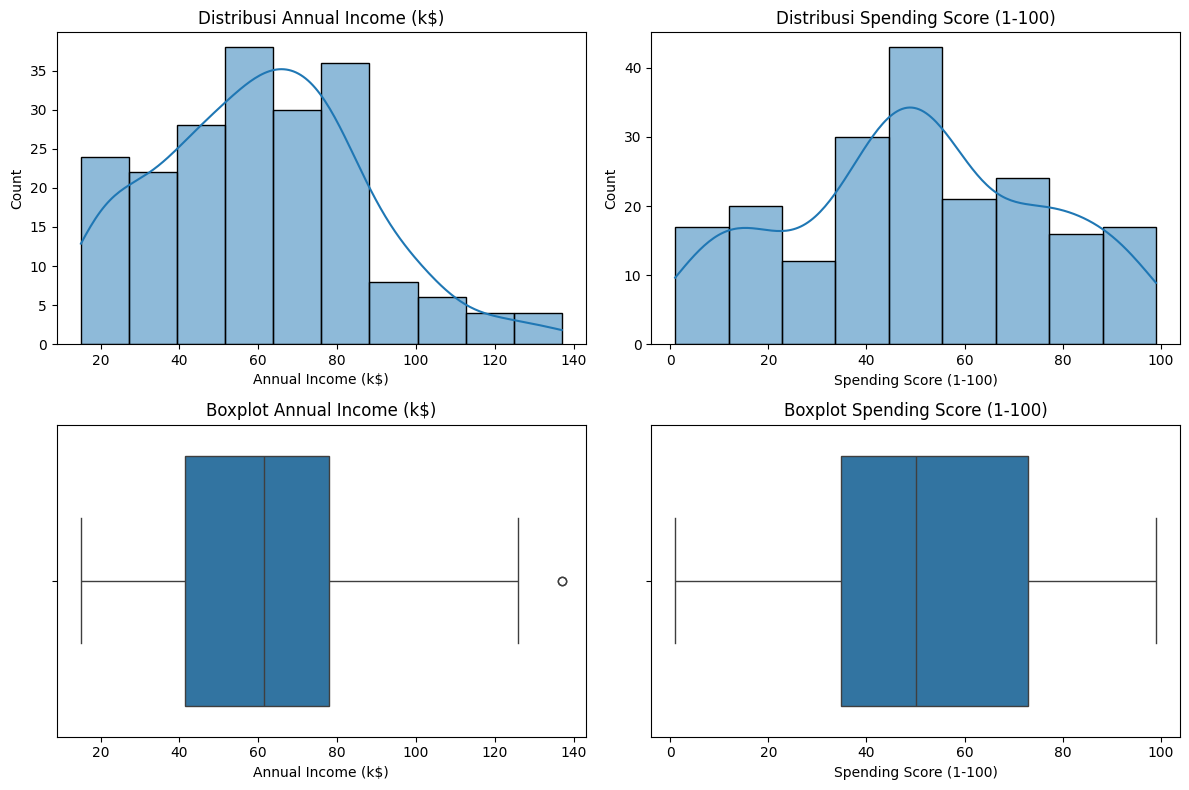

In [3]:
# Tampilkan distribusi Annual Income (k$) dan Spending Score (1-100)
# menggunakan histogram dan/atau boxplot.
# Amati rentang, bentuk distribusi, dan kemungkinan outlier.

fig, ax = plt.subplots(2, 2, figsize= (12, 8))

for i, col in enumerate(['Annual Income (k$)', 'Spending Score (1-100)']):
    sns.histplot(df[col], kde=True, ax=ax[0, i])
    ax[0, i].set_title(f'Distribusi {col}')
    sns.boxplot(x=df[col], ax=ax[1, i])
    ax[1, i].set_title(f'Boxplot {col}')

plt.tight_layout()
plt.show()

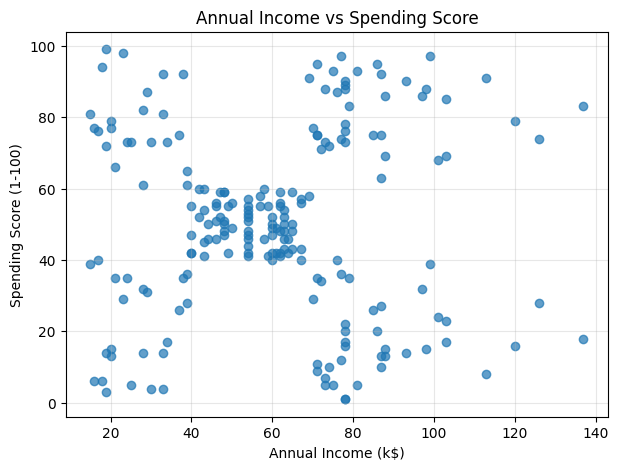

In [4]:
# Buat scatter plot dari Annual Income (k$) terhadap Spending Score (1-100).
# Jangan warnai berdasarkan label apa pun terlebih dahulu.
# Amati apakah terlihat kelompok-kelompok yang terpisah.

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'], alpha=0.7)
ax.set_xlabel('Annual Income (k$)')
ax.set_ylabel('Spending Score (1-100)')
ax.set_title('Annual Income vs Spending Score')
ax.grid(alpha=0.3)
plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

# Jawaban dari Pertanyaan EDA

**Missing value dan duplikat.** Dataset terdiri dari 200 baris dan 5 kolom. `df.isnull().sum()` bernilai 0 untuk semua kolom dan `df.duplicated().sum()` bernilai 0 sehingga tidak ada penanganan khusus yang diperlukan.

**Rentang data.**
- `Annual Income (k$)` berkisar 15 sampai 137 dengan rata-rata 60,56 dan median 61,5. Distribusinya sedikit miring ke kanan (skewness sekitar 0,32). Boxplot menandai dua pelanggan berpendapatan 137k$ sebagai outlier ringan di sisi atas
- `Spending Score (1-100)` berkisar 1 sampai 99 dengan rata-rata 50,2 dan median 50. Distribusinya hampir simetris (skewness sekitar -0,05) dan tidak ada outlier menurut aturan IQR
- Kedua fitur punya skala dan sebaran yang mirip (standar deviasi sekitar 26), jadi tidak ada satu fitur yang jauh mendominasi

**Potensi pengelompokan.** Histogram masing-masing fitur tidak menunjukkan kelompok yang jelas. Kelompok baru terlihat pada scatter plot dua fitur, yang menampakkan sekitar lima kelompok:
1. pendapatan rendah dengan spending tinggi,
2. pendapatan rendah dengan spending rendah,
3. pendapatan sedang dengan spending sedang (kelompok terbesar di tengah),
4. pendapatan tinggi dengan spending tinggi,
5. pendapatan tinggi dengan spending rendah.

Pemisahan antar kelompok cukup jelas, kecuali kelompok tengah yang saling berdekatan dengan kelompok lain. Karena hanya dua fitur yang digunakan, pola ini mudah dilihat secara visual

# 2. Preprocessing

In [ ]:
# Periksa dan tangani missing value serta baris duplikat jika ditemukan.
# Karena CustomerID adalah identitas, jangan masukkan kolom tersebut ke fitur clustering.
# Pilih dua fitur numerik:
#   Annual Income (k$)
#   Spending Score (1-100)
# Simpan dalam DataFrame X.

# data sudah bersih, tetap dicek sebelum lanjut
print(df.isnull().sum().sum(), df.duplicated().sum())

X = df[['Annual Income (k$)', 'Spending Score (1-100)']].copy()

0 0


In [6]:
# Lakukan feature scaling menggunakan StandardScaler.
# Simpan hasilnya sebagai X_scaled.
# Ubah hasil scaling menjadi DataFrame agar nama kolom tetap terlihat.
# Tampilkan beberapa baris X_scaled dan statistik deskriptifnya.

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

display(X_scaled.head())
display(X_scaled.describe().round(3))

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


,Annual Income (k$),Spending Score (1-100)
count,200.000,200.000
mean,-0.000,-0.000
std,1.003,1.003
min,-1.739,-1.910
25%,-0.728,-0.600
50%,0.036,-0.008
75%,0.666,0.885
max,2.918,1.894


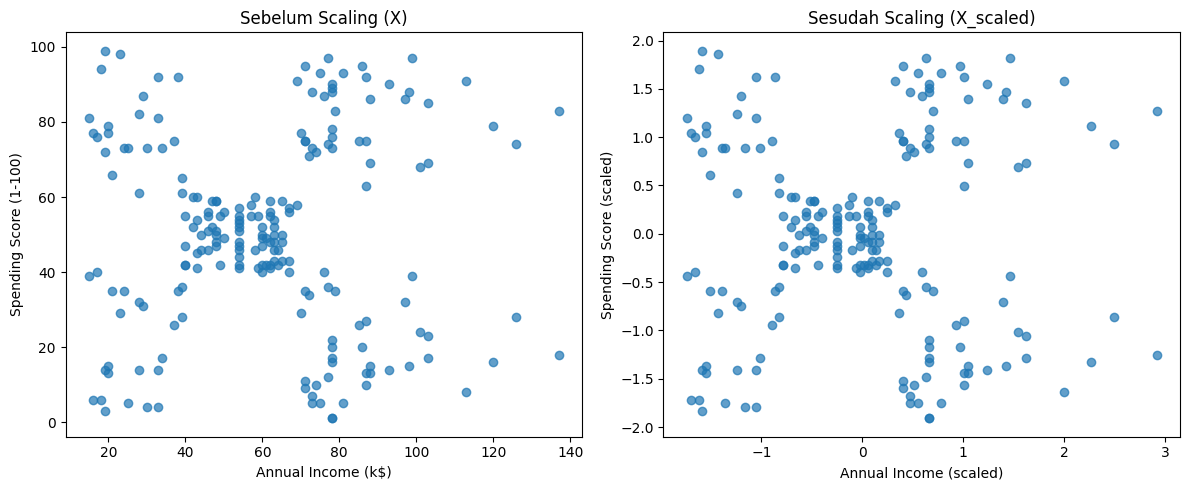

In [7]:
# Buat scatter plot sebelum dan sesudah scaling.
# Jelaskan mengapa scaling penting, terutama ketika algoritma menggunakan jarak
# atau mengasumsikan skala fitur yang sebanding.

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(X.iloc[:, 0], X.iloc[:, 1], alpha=0.7)
ax[0].set_title('Sebelum Scaling (X)')
ax[0].set_xlabel('Annual Income (k$)')
ax[0].set_ylabel('Spending Score (1-100)')

ax[1].scatter(X_scaled.iloc[:, 0], X_scaled.iloc[:, 1], alpha=0.7)
ax[1].set_title('Sesudah Scaling (X_scaled)')
ax[1].set_xlabel('Annual Income (scaled)')
ax[1].set_ylabel('Spending Score (scaled)')

plt.tight_layout()
plt.show()

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

**Alasan memilih kedua fitur ini**
- Keduanya numerik dan langsung menggambarkan perilaku pelanggan: kemampuan finansial (pendapatan) dan kebiasaan belanja (spending score). Kombinasi ini yang umum dipakai untuk segmentasi pelanggan mall.
- Dua fitur dapat divisualisasikan langsung pada bidang 2D, sehingga hasil DBSCAN, BIRCH, dan GMM bisa dinilai secara visual selain lewat metrik.
- Pada scatter plot EDA, kedua fitur sudah menunjukkan struktur kelompok yang jelas.

**Alasan `CustomerID` dikeluarkan**
- Kolom ini hanya nomor urut identitas tanpa makna perilaku. Jika dimasukkan, algoritma berbasis jarak akan menghitung selisih nomor ID sebagai kemiripan antar pelanggan, padahal urutan ID tidak menandakan apa pun. Hasil cluster jadi menyesatkan.

**Alasan `Gender` dikeluarkan**
- Kolom ini bertipe kategorik (Male/Female). DBSCAN, BIRCH, dan GMM bekerja dengan jarak Euclidean atau distribusi Gaussian kontinu, sehingga fitur biner perlu encoding yang tidak natural untuk algoritma ini.
- Fokus eksperimen ada pada perbandingan algoritma pada dua fitur numerik. `Gender` tetap bisa dipakai setelah model selesai, untuk interpretasi cluster.

**Tentang scaling.** Setelah `StandardScaler`, kedua fitur memiliki rata-rata 0 dan standar deviasi sekitar 1 (tampil 1,003 karena `describe()` pandas memakai standar deviasi sampel). Bentuk sebaran titik tidak berubah, hanya skalanya. Hal ini penting karena `eps` DBSCAN dan `threshold` BIRCH dinyatakan dalam satuan jarak, sehingga fitur dengan skala lebih besar akan mendominasi perhitungan jarak jika tidak distandarisasi.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [8]:
# Jalankan DBSCAN pada X_scaled.
# Mulai dengan eps dan min_samples yang masuk akal, misalnya eps=0.3 dan min_samples=5.
# Simpan label hasil clustering sebagai labels_dbscan.
# Catatan: nilai eps perlu dicoba dan dievaluasi, bukan dianggap pasti paling baik.

db_model = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = db_model.fit_predict(X_scaled)

In [9]:
# Tampilkan jumlah anggota setiap label hasil DBSCAN.
# Hitung jumlah cluster dengan tidak memasukkan label -1.
# Hitung juga jumlah titik noise (label -1).

print(pd.Series(labels_dbscan).value_counts().sort_index())

n_clusters = len(set(labels_dbscan))- (1 if -1 in labels_dbscan else 0)
n_noise = (labels_dbscan == -1).sum()
print('Jumlah cluster:', n_clusters)
print('Jumlah noise  :', n_noise)


-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64
Jumlah cluster: 7
Jumlah noise  : 35


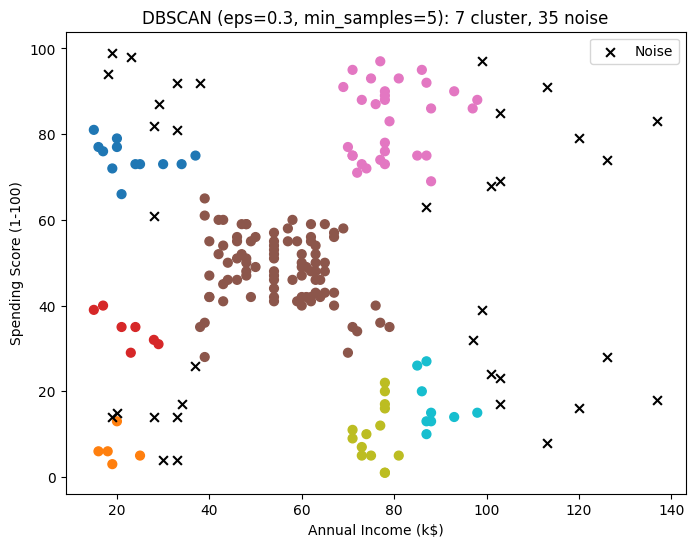

In [10]:
# Buat scatter plot hasil DBSCAN berdasarkan labels_dbscan.
# Gunakan X_scaled atau X untuk koordinat plot; untuk interpretasi, X (fitur asli)
# biasanya lebih mudah dipahami.
# Beri judul dan label sumbu yang jelas, serta pastikan noise dapat dibedakan.

noise = labels_dbscan == -1

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X.loc[~noise].iloc[:, 0], X.loc[~noise].iloc[:, 1],
           c=labels_dbscan[~noise], cmap='tab10', s=40)
ax.scatter(X.loc[noise].iloc[:, 0], X.loc[noise].iloc[:, 1],
           c='black', marker='x', s=40, label='Noise')

ax.set_xlabel('Annual Income (k$)')
ax.set_ylabel('Spending Score (1-100)')
ax.set_title(f'DBSCAN (eps=0.3, min_samples=5): {n_clusters} cluster, {n_noise} noise')
ax.legend()
plt.show()

In [11]:
# Coba beberapa kombinasi eps dan min_samples.
# Buat tabel ringkasan yang berisi eps, min_samples, jumlah cluster (tanpa noise),
# jumlah noise, dan Silhouette Score jika metrik tersebut valid.
# Hindari menghitung silhouette jika hasilnya hanya satu cluster atau semua titik noise.

rows = []
for eps in [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]:
    for ms in [3, 5, 7]:
        lb = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        k = len(set(lb)) - (1 if -1 in lb else 0)
        mask = lb != -1
        sil = silhouette_score(X_scaled[mask], lb[mask]) if k > 1 else np.nan
        rows.append({'eps': eps, 'min_samples' : ms, 'n_clusters': k,
                     'n_noise': (~mask).sum(), 'silhouette_score': sil })

db_eval = pd.DataFrame(rows)
db_eval.round(4)

,eps,min_samples,n_clusters,n_noise,silhouette_score
0,0.20,3,13,44,0.4697
1,0.20,5,7,77,0.5856
2,0.20,7,4,100,0.6094
3,0.25,3,12,16,0.4090
4,0.25,5,6,50,0.5317
5,0.25,7,5,77,0.5945
6,0.30,3,9,14,0.4720
7,0.30,5,7,35,0.5243
8,0.30,7,4,72,0.6452
9,0.35,3,7,11,0.5154


### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

**Hasil awal.** Dengan `eps=0.3` dan `min_samples=5`, DBSCAN menghasilkan 7 cluster dan 35 titik noise (17,5% data). Cluster terbesar berisi 88 titik, yaitu kelompok tengah, sedangkan cluster terkecil hanya berisi 5 titik.

**Pengaruh `eps`** (dibaca dari tabel pada `min_samples=5`)
- Jumlah noise turun konsisten seiring `eps` naik: 77, 50, 35, 23, 15, 11, 8 untuk `eps` 0,2 sampai 0,5. Radius yang lebih besar membuat lebih banyak titik terjangkau oleh titik inti.
- Jumlah cluster tidak turun secara monoton. Pada `eps` kecil beberapa kelompok pecah menjadi cluster kecil atau terbuang sebagai noise. Pada `eps` besar cluster yang berdekatan menyatu: 4 cluster pada `eps=0.4`, 3 pada 0,45, dan hanya 2 pada 0,5. Pada titik ini kelompok-kelompok yang sebenarnya berbeda sudah tergabung karena terhubung oleh titik-titik penghubung.

**Pengaruh `min_samples`** (pada `eps` tetap)
- `min_samples` yang lebih besar mensyaratkan area yang lebih padat agar sebuah titik menjadi titik inti, sehingga noise naik dan jumlah cluster turun. Pada `eps=0.3`: `min_samples=3` memberi 9 cluster dan 14 noise, `min_samples=5` memberi 7 cluster dan 35 noise, `min_samples=7` memberi 4 cluster dan 72 noise.
- `min_samples` yang kecil membuat DBSCAN terlalu longgar. Cluster mudah pecah menjadi kelompok-kelompok kecil, misalnya 13 cluster pada `eps=0.2, min_samples=3`.

**Kombinasi yang bermasalah**
- *Terlalu banyak noise:* `eps=0.2` dengan `min_samples=7` membuang 100 titik (50% data), dan `eps=0.3` dengan `min_samples=7` membuang 72 titik (36%).
- *Cluster terlalu sedikit atau menyatu:* `eps=0.5` hanya menghasilkan 2 cluster untuk semua nilai `min_samples`.
- *Silhouette tinggi yang menyesatkan:* nilai silhouette tertinggi (0,645 pada `eps=0.3, min_samples=7`) justru berasal dari konfigurasi dengan noise sangat banyak. Silhouette DBSCAN dihitung tanpa noise, sehingga titik-titik yang sulit dibuang dan skor naik. Nilai ini tidak boleh dibaca sendirian.

**Parameter yang dipilih untuk perbandingan akhir:** `eps=0.35`, `min_samples=5`. Hasilnya 6 cluster dengan 23 noise (11,5%) dan silhouette 0,558. Ini adalah kompromi yang wajar antara jumlah noise yang terkendali dan cluster yang masih terpisah.

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [12]:
# Latih model Birch pada X_scaled.
# Coba threshold awal, misalnya 0.5, dan n_clusters=5.
# Simpan label hasil clustering sebagai labels_birch.
# Catatan: jumlah cluster akhir dapat berubah sesuai parameter yang digunakan.

birch_model = Birch(threshold= 0.5, n_clusters= 5)
labels_birch = birch_model.fit_predict(X_scaled)

In [13]:
# Tampilkan jumlah anggota setiap cluster BIRCH.
# Tampilkan juga jumlah cluster yang terbentuk.

print(pd.Series(labels_birch).value_counts().sort_index())
print('Jumlah cluster:', len(np.unique(labels_birch)))


0     36
1    109
2      8
3     25
4     22
Name: count, dtype: int64
Jumlah cluster: 5


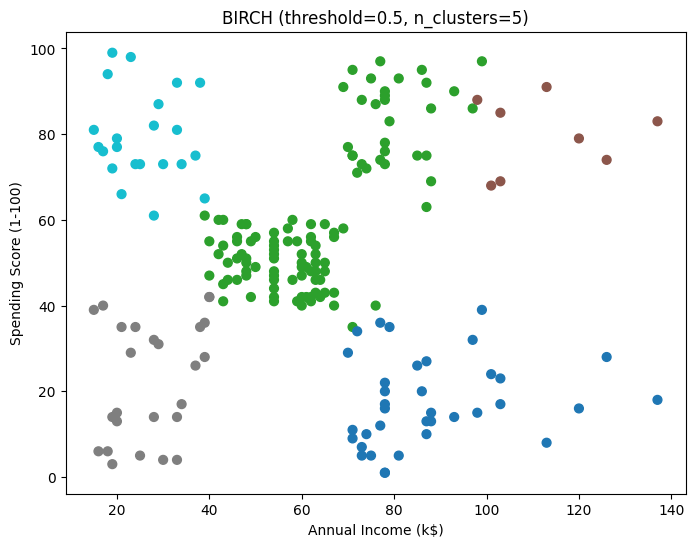

In [14]:
# Buat scatter plot hasil BIRCH pada ruang fitur asli X.
# Warnai titik berdasarkan labels_birch.

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X.iloc[:, 0], X.iloc[:, 1], c=labels_birch, cmap='tab10', s=40)
ax.set_xlabel('Annual Income (k$)')
ax.set_ylabel('Spending Score (1-100)')
ax.set_title('BIRCH (threshold=0.5, n_clusters=5)')
plt.show()

In [15]:
# Bandingkan beberapa nilai threshold (misalnya 0.3, 0.5, 0.7, 1.0)
# dengan jumlah cluster akhir yang sama jika memungkinkan.
# Buat tabel berisi threshold, jumlah cluster, dan Silhouette Score bila valid.

rows = []
for t in [0.3, 0.5, 0.7, 1.0]:
    b = Birch(threshold=t, n_clusters=5).fit(X_scaled)
    lb = b.labels_
    rows.append({'threshold': t,
                 'n_subcluster': len(b.subcluster_centers_),
                 'n_clusters': len(np.unique(lb)),
                 'silhouette_score': silhouette_score(X_scaled, lb)})

birch_eval = pd.DataFrame(rows)
birch_eval.round(4)

c:\Users\fauza\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\cluster\_birch.py:711: ConvergenceWarning: Number of subclusters found (4) by BIRCH is less than (5). Decrease the threshold.
  warnings.warn(


,threshold,n_subcluster,n_clusters,silhouette_score
0,0.3,23,5,0.4781
1,0.5,10,5,0.4145
2,0.7,6,5,0.4207
3,1.0,4,4,0.3886


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

### Analisis BIRCH

**Pengaruh `threshold`.** `threshold` menentukan radius maksimum sebuah subcluster pada CF-Tree. Semakin besar `threshold`, semakin sedikit subcluster yang terbentuk: 23, 10, 6, dan 4 subcluster untuk `threshold` 0,3, 0,5, 0,7, dan 1,0. Selama jumlah subcluster masih di atas `n_clusters`, jumlah cluster akhir tetap 5. Pada `threshold=1.0` subcluster hanya 4, lebih sedikit dari 5, sehingga cluster akhir hanya 4 dan sklearn menampilkan `ConvergenceWarning`. Silhouette juga cenderung menurun, dari 0,478 (`threshold=0.3`) menjadi 0,389 (`threshold=1.0`), karena ringkasan yang terlalu kasar membuat batas antar cluster kabur. Pada eksperimen ini `threshold=0.3` memberi hasil terbaik.

**Titik yang jauh dari kelompok utama: BIRCH vs DBSCAN**
- DBSCAN menandai titik yang tidak memenuhi kepadatan sebagai noise (label -1) dan memisahkannya dari cluster.
- BIRCH tidak punya konsep noise. Setiap titik harus masuk ke suatu subcluster, lalu ke cluster akhir. Titik yang jauh akan menempati subcluster sendiri, atau ikut bergabung dengan cluster terdekat, atau membentuk cluster kecil. Pada `threshold=0.5`, cluster kecil berisi 8 titik berpendapatan sangat tinggi, dan pada `threshold=0.3` ada cluster berisi 3 titik. Cluster kecil seperti ini memakai "jatah" salah satu dari 5 cluster, sehingga kelompok lain bisa menjadi tergabung.

**Pengaruh `n_clusters`.** Ketika `n_clusters` diberikan, BIRCH menjalankan langkah global (agglomerative) yang menggabungkan subcluster menjadi jumlah cluster yang diminta. Jumlah cluster akhir pun terkunci dan tidak ditentukan oleh data. Karena itu hasilnya sangat bergantung pada kualitas subcluster dari `threshold`. Pada `threshold=0.5`, cluster terbesar berisi 109 titik, menunjukkan beberapa kelompok yang berdekatan tergabung. Jika `n_clusters=None`, label yang dikembalikan adalah label subcluster, sehingga jumlah cluster mengikuti `threshold`.

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [16]:
# Latih GaussianMixture pada X_scaled menggunakan EM.
# Mulai dengan n_components=5, covariance_type='full', dan random_state=42.
# Simpan label hasil prediksi sebagai labels_gmm.

gmm_model = GaussianMixture(n_components=5, covariance_type='full', random_state=42)
labels_gmm = gmm_model.fit_predict(X_scaled)


In [17]:
# Tampilkan jumlah anggota setiap cluster GMM.
# Gunakan predict_proba untuk melihat probabilitas keanggotaan tiap titik.
# Tampilkan beberapa baris probabilitas dan periksa apakah ada titik dengan
# keanggotaan yang relatif tidak pasti.

print(pd.Series(labels_gmm).value_counts().sort_index())

proba = gmm_model.predict_proba(X_scaled)
proba_df = pd.DataFrame(proba, columns=[f'Cluster {i}' for i in range(5)]).round(3)
display(proba_df.head(10))

max_prob = proba.max(axis=1)
print('Titik dengan probabilitas maks < 0.9:', (max_prob < 0.9).sum())
display(proba_df.assign(max_prob=max_prob.round(3))[max_prob < 0.7])

0    84
1    39
2    21
3    33
4    23
Name: count, dtype: int64


,Cluster 0,Cluster 1,Cluster 2,Cluster 3,Cluster 4
0,0.000,0.0,0.001,0.0,0.999
1,0.000,0.0,1.000,0.0,0.000
2,0.000,0.0,0.000,0.0,1.000
3,0.000,0.0,1.000,0.0,0.000
4,0.000,0.0,0.002,0.0,0.998
5,0.000,0.0,1.000,0.0,0.000
6,0.000,0.0,0.000,0.0,1.000
7,0.000,0.0,1.000,0.0,0.000
8,0.000,0.0,0.000,0.0,1.000
9,0.001,0.0,0.998,0.0,0.000


Titik dengan probabilitas maks < 0.9: 8


,Cluster 0,Cluster 1,Cluster 2,Cluster 3,Cluster 4,max_prob
27,0.279,0.0,0.675,0.000,0.046,0.675
48,0.611,0.0,0.000,0.000,0.388,0.611
49,0.611,0.0,0.000,0.000,0.388,0.611
124,0.497,0.0,0.000,0.503,0.000,0.503


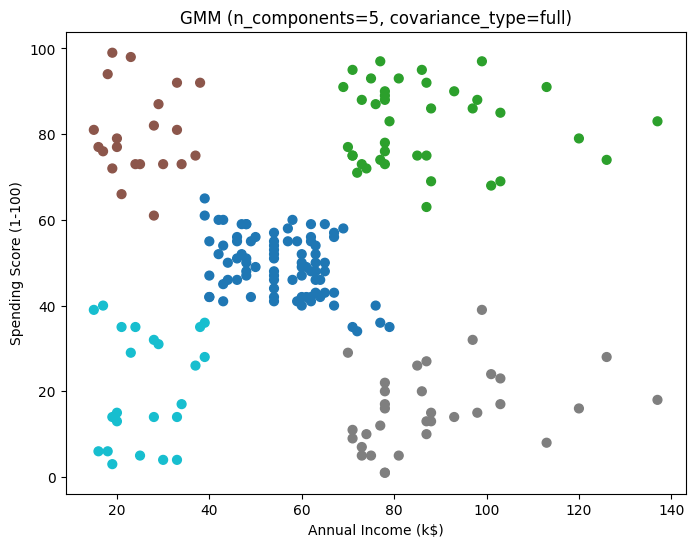

In [18]:
# Buat scatter plot hasil GMM pada ruang fitur asli X.
# Warnai titik berdasarkan labels_gmm.

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X.iloc[:, 0], X.iloc[:, 1], c= labels_gmm, cmap='tab10', s=40 )
ax.set_xlabel('Annual Income (k$)')
ax.set_ylabel('Spending Score (1-100)')
ax.set_title('GMM (n_components=5, covariance_type=full)')
plt.show()

In [19]:
# Bandingkan beberapa nilai n_components (misalnya 2 sampai 8).
# Catat Silhouette Score dan BIC untuk setiap model.
# BIC yang lebih rendah menunjukkan keseimbangan model dan kecocokan data yang lebih baik
# menurut kriteria BIC, tetapi tetap perlu dipertimbangkan bersama visualisasi dan konteks.

rows = []
for k in range(2, 9):
    g = GaussianMixture(n_components=k, covariance_type='full', random_state=42).fit(X_scaled)
    rows.append({'n_components': k,
                 'silhouette_score': silhouette_score(X_scaled, g.predict(X_scaled)),
                 'bic': g.bic(X_scaled)})

gmm_eval = pd.DataFrame(rows)
gmm_eval.round(3)

,n_components,silhouette_score,bic
0,2,0.379,1153.905
1,3,0.430,1151.718
2,4,0.413,1103.790
3,5,0.554,1058.652
4,6,0.517,1074.683
5,7,0.509,1087.329
6,8,0.430,1102.371


### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

### Analisis EM/GMM

**Makna probabilitas keanggotaan.** `predict_proba` menghasilkan probabilitas posterior bahwa suatu titik berasal dari tiap komponen Gaussian, dan jumlahnya 1 untuk setiap titik. Ini adalah soft assignment, berbeda dari DBSCAN dan BIRCH yang memberi label tunggal. Pada data ini, sebagian besar titik punya probabilitas maksimum mendekati 1 (misalnya 0,999), artinya cluster-nya jelas. Ada 8 titik dengan probabilitas maksimum di bawah 0,9, dan beberapa mendekati 0,5 sampai 0,6. Itu titik yang berada di perbatasan dua komponen dan keanggotaannya tidak pasti, sesuatu yang tidak terlihat pada label keras.

**Pengaruh `n_components`.** Nilai kecil memaksa kelompok yang berbeda tergabung dalam satu Gaussian (underfitting). Nilai besar memecah kelompok yang sama menjadi beberapa komponen (overfitting). Pada tabel, `n_components=5` memberi silhouette tertinggi (0,554), dan setelah itu silhouette menurun (0,517 pada 6 komponen dan 0,430 pada 8 komponen).

**Mengapa jumlah cluster harus ditentukan sebelum training.** Model GMM adalah campuran dengan jumlah komponen tertentu. Jumlah komponen menentukan struktur model (berapa mean, kovarians, dan bobot yang diestimasi), sehingga harus ditetapkan sebelum EM dijalankan. EM hanya mengestimasi parameter untuk struktur tersebut dan tidak dapat memilih jumlah komponen sendiri. Karena itu dipakai kriteria seperti BIC dan silhouette untuk membandingkan beberapa nilai.

**Silhouette tertinggi vs BIC terendah.** Ya, keduanya jatuh pada model yang sama, yaitu `n_components=5`: silhouette 0,554 dan BIC 1058,65, terendah di antara semua kandidat (BIC pada 4 komponen 1103,79 dan pada 6 komponen 1074,68). Kesepakatan dua kriteria yang berbeda sudut pandang ini memperkuat pilihan 5 komponen, karena BIC menilai kecocokan model terhadap data (dengan penalti kompleksitas) sedangkan silhouette menilai kerapatan dan keterpisahan cluster. Keduanya tidak selalu sejalan, jadi hasilnya tetap perlu dicek bersama visualisasi.

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [20]:
# Buat fungsi evaluasi yang menerima X_scaled dan label clustering.
# Untuk DBSCAN, hitung metrik pada titik non-noise saja.
# Pastikan metrik hanya dihitung jika terdapat setidaknya 2 cluster
# dan jumlah cluster lebih kecil daripada jumlah titik yang dievaluasi.

def evaluate_clustering(X, labels):
    labels = np.asarray(labels)
    mask = labels != -1
    X_eval, lab = X[mask], labels[mask]
    n = len(np.unique(lab))
    if n < 2 or n >= len(X_eval):
        return np.nan, np.nan, np.nan
    return (silhouette_score(X_eval, lab),
            davies_bouldin_score(X_eval, lab),
            calinski_harabasz_score(X_eval, lab))

In [21]:
# Evaluasi hasil terbaik dari DBSCAN, BIRCH, dan GMM.
# Sajikan ringkasan dalam satu DataFrame/tabel:
# model, jumlah cluster, jumlah noise, silhouette, Davies-Bouldin, Calinski-Harabasz.
# Untuk BIRCH dan GMM, jumlah noise dapat ditulis 0 atau N/A karena algoritma
# tersebut tidak menandai noise secara eksplisit.

# parameter terbaik dari eksperimen sebelumnya
best_db = DBSCAN(eps=0.35, min_samples=5).fit_predict(X_scaled)
best_birch = Birch(threshold=0.3, n_clusters=5).fit_predict(X_scaled)
best_gmm = GaussianMixture(n_components=5, covariance_type='full', random_state=42).fit_predict(X_scaled)

models = {'DBSCAN': best_db, 'BIRCH': best_birch, 'GMM': best_gmm}

rows = []
for name, lb in models.items():
    sil, dbi, ch = evaluate_clustering(X_scaled, lb)
    rows.append({'Model': name,
                 'Jumlah Cluster': len(set(lb)) - (1 if -1 in lb else 0),
                 'Jumlah Noise': (lb == -1).sum(),
                 'Silhouette': sil,
                 'Davies-Bouldin': dbi,
                 'Calinski-Harabasz': ch})

eval_df = pd.DataFrame(rows)
eval_df.round(3)

,Model,Jumlah Cluster,Jumlah Noise,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,DBSCAN,6,23,0.558,0.511,245.356
1,BIRCH,5,0,0.478,0.648,144.013
2,GMM,5,0,0.554,0.576,244.940


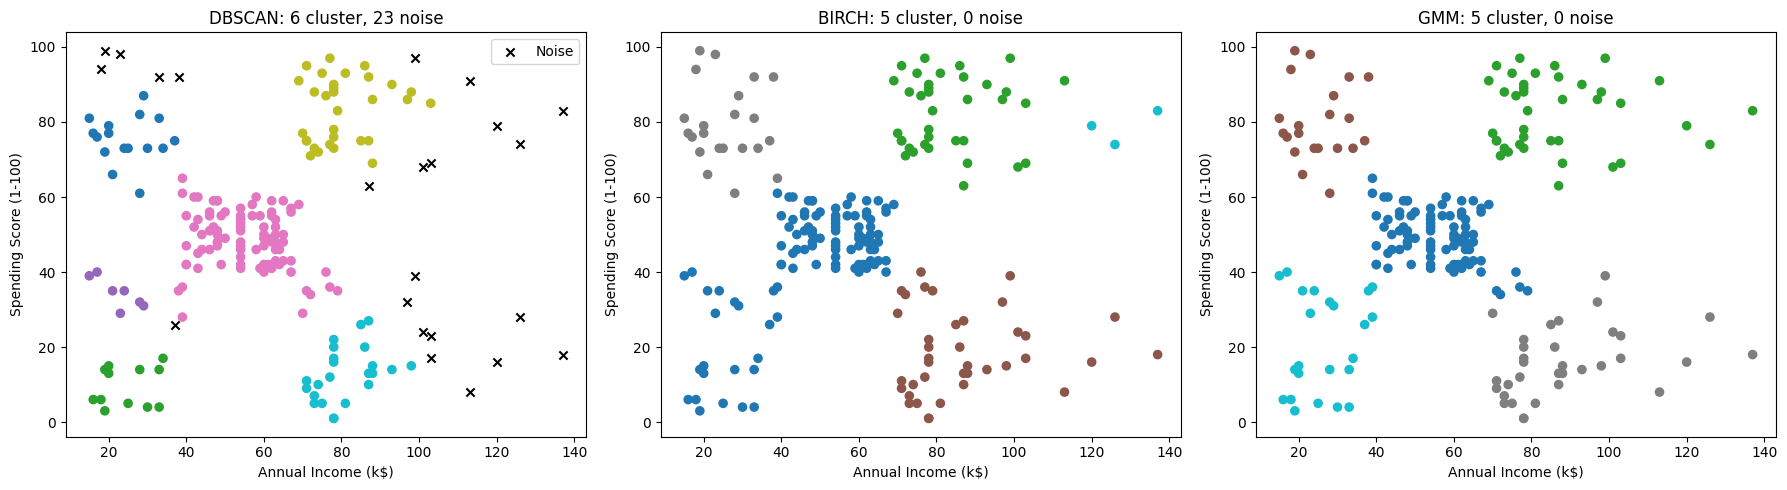

In [22]:
# Buat tiga scatter plot dalam satu baris subplot:
# DBSCAN, BIRCH, dan GMM.
# Gunakan koordinat dari fitur asli X dan warna berdasarkan label cluster.
# Beri judul yang menunjukkan algoritma dan jumlah cluster/noise.

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, lb) in zip(axes, models.items()):
    noise = lb == -1
    k = len(set(lb)) - (1 if -1 in lb else 0)
    ax.scatter(X.loc[~noise].iloc[:, 0], X.loc[~noise].iloc[:, 1],
               c=lb[~noise], cmap='tab10', s=35)
    if noise.any():
        ax.scatter(X.loc[noise].iloc[:, 0], X.loc[noise].iloc[:, 1],
                   c='black', marker='x', s=35, label='Noise')
        ax.legend()
    ax.set_title(f'{name}: {k} cluster, {noise.sum()} noise')
    ax.set_xlabel('Annual Income (k$)')
    ax.set_ylabel('Spending Score (1-100)')

plt.tight_layout()
plt.show()

In [23]:
# Buat profil cluster pada fitur asli.
# Untuk setiap algoritma, tampilkan jumlah anggota serta median dan rata-rata
# Annual Income (k$) dan Spending Score (1-100) untuk setiap cluster.
# Untuk DBSCAN, analisis label -1 (noise) secara terpisah.

for name, lb in models.items():
    d = X.copy()
    d['cluster'] = lb

    prof = d[d['cluster'] != -1].groupby('cluster').agg(
        n=('Annual Income (k$)', 'count'),
        income_median=('Annual Income (k$)', 'median'),
        income_mean=('Annual Income (k$)', 'mean'),
        score_median=('Spending Score (1-100)', 'median'),
        score_mean=('Spending Score (1-100)', 'mean')).round(1)

    print(f'--- {name} ---')
    display(prof)

    if name == 'DBSCAN':
        print('Noise DBSCAN:')
        display(d.loc[d['cluster'] == -1, X.columns]
                 .agg(['count', 'mean', 'median', 'min', 'max']).round(1))

--- DBSCAN ---


,n,income_median,income_mean,score_median,score_mean
cluster,,,,,
0,16,24.5,24.8,75.5,75.4
1,12,22.5,24.6,9.5,9.6
2,7,23.0,22.4,35.0,34.4
3,88,54.0,55.2,49.0,48.6
4,31,78.0,80.3,86.0,83.2
5,23,78.0,81.0,13.0,12.8


Noise DBSCAN:


,Annual Income (k$),Spending Score (1-100)
count,23.0,23.0
mean,89.3,57.8
median,101.0,68.0
min,18.0,8.0
max,137.0,99.0


--- BIRCH ---


,n,income_median,income_mean,score_median,score_mean
cluster,,,,,
0,101,50.0,48.2,47.0,43.4
1,36,78.0,83.1,85.5,82.4
2,38,80.0,87.0,16.5,18.6
3,22,24.5,25.7,77.0,79.4
4,3,126.0,127.7,79.0,78.7


--- GMM ---


,n,income_median,income_mean,score_median,score_mean
cluster,,,,,
0,84,55.5,55.6,49.5,49.4
1,39,79.0,86.5,83.0,82.1
2,21,24.0,25.1,77.0,80.0
3,33,86.0,88.8,15.0,16.0
4,23,25.0,26.3,17.0,20.9


### Ringkasan Perbandingan

Lengkapi tabel atau tuliskan rangkuman berdasarkan hasil eksperimen:

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak. Jumlah cluster muncul dari `eps` dan `min_samples`. | Opsional. Bisa diberi `n_clusters`, atau `None` agar mengikuti subcluster. | Ya. `n_components` harus ditetapkan sebelum training. |
| Dapat memberi label noise secara eksplisit? | Ya, label -1. | Tidak. Semua titik dipaksa masuk cluster. | Tidak. Tetapi probabilitas rendah menandai titik yang tidak pasti. |
| Parameter yang paling memengaruhi hasil | `eps` dan `min_samples` | `threshold` dan `n_clusters` | `n_components`, `covariance_type`, dan inisialisasi (`random_state`) |
| Bentuk cluster yang dapat dimodelkan | Bentuk bebas berdasarkan kepadatan | Cenderung bulat (compact) karena ringkasan subcluster dan penggabungan global | Elips (dengan `covariance_type='full'`), dengan ukuran dan orientasi berbeda |
| Kelebihan | Mendeteksi outlier, tidak perlu jumlah cluster, bisa membentuk cluster tidak beraturan | Cepat dan hemat memori, cocok untuk data besar dan data streaming | Soft assignment (probabilitas), cluster elips fleksibel, ada kriteria BIC untuk memilih model |
| Kekurangan | Sensitif terhadap `eps`, kesulitan jika kepadatan antar cluster berbeda, silhouette-nya sulit dibandingkan karena noise dibuang | Tidak punya noise, bergantung pada `threshold`, cluster kecil dari outlier memakai jatah cluster, kualitas lebih rendah pada data kecil ini | Harus tahu jumlah komponen, bisa terjebak optimum lokal, mengasumsikan data berasal dari distribusi Gaussian |

**Hasil metrik (parameter terbaik)**

| Model | Jumlah Cluster | Noise | Silhouette | Davies-Bouldin | Calinski-Harabasz |
|---|---|---|---|---|---|
| DBSCAN (eps=0.35, min_samples=5) | 6 | 23 | 0,558 | 0,511 | 245,36 |
| BIRCH (threshold=0.3, n_clusters=5) | 5 | 0 | 0,478 | 0,648 | 144,01 |
| GMM (n_components=5, full) | 5 | 0 | 0,554 | 0,576 | 244,94 |

Metrik DBSCAN dihitung hanya pada 177 titik non-noise, sedangkan BIRCH dan GMM pada seluruh 200 titik, sehingga perbandingannya tidak sepenuhnya setara.


# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?

1. DBSCAN dan BIRCH bekerja dengan jarak Euclidean, dan GMM dengan kovarians, sehingga fitur dengan skala atau varians lebih besar akan mendominasi. Scaling membuat tiap fitur memiliki bobot sebanding (rata-rata 0 dan standar deviasi 1). Parameter seperti `eps=0.3` dan `threshold=0.3` juga jadi bermakna: keduanya dinyatakan dalam satuan standar deviasi, bukan k$ atau poin skor. Perlu dicatat, pada dataset ini dampaknya relatif moderat karena kedua fitur sudah berskala mirip (standar deviasi 26,3 vs 25,8, rentang 122 vs 98). Scaling tetap diperlukan demi konsistensi dan agar parameter mudah ditafsirkan, terutama jika nanti fitur lain seperti `Age` ditambahkan.

2. Kenaikan `eps` menurunkan jumlah noise secara konsisten (77 menjadi 8 pada `min_samples=5` untuk `eps` 0,2 sampai 0,5), tetapi cluster yang berdekatan mulai menyatu: 7 cluster pada `eps=0.2`, 4 pada 0,4, dan 2 pada 0,5. Kenaikan `min_samples` menaikkan noise dan menurunkan jumlah cluster (pada `eps=0.3`: 9 cluster dan 14 noise, 7 dan 35, 4 dan 72). Kombinasi bermasalah: `eps=0.2, min_samples=7` membuang 50% data sebagai noise, sedangkan `eps=0.5` hanya menyisakan 2 cluster. Skor silhouette tertinggi (0,645 pada `eps=0.3, min_samples=7`) berasal dari konfigurasi dengan 72 titik noise, sehingga tidak bisa dijadikan acuan tunggal. Karena itu dipilih `eps=0.35, min_samples=5` (6 cluster, 23 noise).

3. `threshold` yang lebih besar menghasilkan subcluster lebih sedikit (23, 10, 6, 4 untuk 0,3, 0,5, 0,7, 1,0) dan silhouette cenderung turun (0,478 menjadi 0,389). Pada `threshold=1.0` subcluster (4) lebih sedikit dari `n_clusters` (5), sehingga hanya 4 cluster terbentuk dan muncul peringatan. `n_clusters` mengunci jumlah cluster akhir lewat penggabungan global, sehingga kualitas hasil bergantung pada subcluster yang dibentuk `threshold`. Pada `threshold=0.5` cluster terbesar menampung 109 titik karena beberapa kelompok tergabung, sedangkan `threshold=0.3` memisahkan kelompok dengan lebih baik.

4. Probabilitas keanggotaan adalah posterior P(komponen k | titik x), yaitu seberapa besar kemungkinan titik berasal dari tiap Gaussian. Pada tahap E-step, EM menghitung probabilitas ini (sering disebut responsibility) untuk setiap titik dari parameter saat ini. Pada tahap M-step, EM memperbarui bobot, mean, dan kovarians tiap komponen sebagai rata-rata berbobot responsibility, sehingga titik berkontribusi pada beberapa komponen sesuai probabilitasnya. Kedua langkah diulang sampai log-likelihood konvergen. Pada hasil ini, sebagian besar titik punya probabilitas maksimum mendekati 1, sedangkan 8 titik berada di bawah 0,9 dan beberapa berada sekitar 0,5 sampai 0,6 (batas antar dua cluster).

5. GMM dengan 5 komponen menurut saya paling mudah diinterpretasikan. Kelima cluster-nya sesuai dengan pola yang terlihat pada EDA (rendah-rendah, rendah-tinggi, tengah, tinggi-rendah, tinggi-tinggi), seluruh pelanggan memiliki segmen, dan probabilitasnya menunjukkan seberapa yakin penetapan tiap pelanggan. DBSCAN juga mudah dibaca secara visual, tetapi menghasilkan 6 cluster termasuk satu cluster kecil (7 titik) yang kurang bermakna bisnis, ditambah 23 noise yang harus ditangani terpisah. BIRCH paling sulit dibaca karena satu clusternya hanya berisi 3 titik dan kelompok pendapatan rendah dengan spending rendah menyatu ke cluster tengah.

6. Tidak sepenuhnya. DBSCAN unggul pada Silhouette (0,558) dan Davies-Bouldin (0,511), sedangkan Calinski-Harabasz DBSCAN (245,36) dan GMM (244,94) hampir sama. BIRCH terendah di ketiga metrik. Perbedaan DBSCAN dan GMM kemungkinan disebabkan oleh: (a) DBSCAN dievaluasi hanya pada 177 titik non-noise, titik-titik yang sulit sudah dibuang sehingga skornya cenderung lebih tinggi; (b) metrik internal seperti Silhouette dan CH mengasumsikan cluster kompak dan cembung, yang cocok dengan hasil GMM dan DBSCAN pada data ini; (c) jumlah cluster berbeda (6 vs 5), padahal metrik sensitif terhadap jumlah cluster. Karena itu metrik harus dibaca bersama visualisasi dan konteks bisnis, bukan sebagai penentu tunggal. Jika harus memilih model yang mencakup semua pelanggan, GMM adalah yang terbaik.

7. Karakteristik cluster dan nama deskriptif (berdasarkan profil GMM).
- *Pelanggan Reguler* (sekitar 84 orang): pendapatan median sekitar 55k$ dan spending score sekitar 49.
- *Premium / Big Spender* (sekitar 39 orang): pendapatan tinggi (median sekitar 79k$) dan spending score sekitar 83.
- *Antusias Berbudget Kecil* (sekitar 21 orang): pendapatan rendah (sekitar 24k$) tetapi spending score tinggi (sekitar 77).
- *Berpenghasilan Tinggi tapi Hemat* (sekitar 33 orang): pendapatan sekitar 86k$ tetapi spending score hanya sekitar 15. Ini segmen dengan potensi yang belum tergarap.
- *Pasif / Hemat* (sekitar 23 orang): pendapatan rendah (sekitar 25k$) dan spending score rendah (sekitar 17).

Profil DBSCAN dan BIRCH menunjukkan pola serupa. Noise DBSCAN punya pendapatan median sekitar 101k$ dan spending score yang bervariasi, jadi mereka adalah pelanggan atipikal, terutama berpendapatan sangat tinggi. BIRCH membentuk satu cluster kecil (3 orang, pendapatan median sekitar 126k$) dan menyatukan kelompok pasif/hemat ke dalam cluster tengah.


8. Keterbatasan dua fitur dan dataset kecil.
- Dua fitur mengabaikan informasi lain seperti `Age` dan `Gender`, sehingga dua pelanggan dengan pendapatan dan skor sama tetapi usia berbeda dianggap identik. Segmentasi yang lebih kaya bisa muncul dengan fitur tambahan.
- Dengan hanya 200 titik, estimasi kepadatan DBSCAN tidak stabil (hasil sangat berubah untuk perubahan kecil `eps`), dan GMM `full` pada 5 komponen menaksir 29 parameter dari 200 titik, sehingga rentan terhadap overfitting dan inisialisasi acak.
- BIRCH dirancang untuk data besar, jadi keunggulan utamanya (efisiensi) tidak terlihat pada dataset sekecil ini.
- `Spending Score` adalah skor buatan mall tanpa label kebenaran (ground truth), sehingga validasi hanya bisa lewat metrik internal dan penilaian visual. Dataset ini juga tergolong dataset latihan, sehingga pola kelompoknya lebih rapi daripada data pelanggan nyata.

# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

**Algoritma terbaik untuk dataset ini.** GMM dengan `n_components=5` adalah pilihan yang paling bermanfaat untuk segmentasi pelanggan. Model ini menetapkan seluruh 200 pelanggan ke segmen, silhouette 0,554 dan Calinski-Harabasz 244,94 hampir setara DBSCAN, dan BIC terendah (1058,65) berada pada 5 komponen yang sama dengan silhouette tertinggi. Kelima segmen juga mudah dinamai secara bisnis. DBSCAN (`eps=0.35`, `min_samples=5`) sangat baik sebagai pelengkap karena mengisolasi 23 pelanggan atipikal (noise), tetapi satu clusternya kecil dan sebagian pelanggan tidak mendapat segmen. BIRCH paling lemah (silhouette 0,478, Davies-Bouldin 0,648, Calinski-Harabasz 144,01), terutama karena cluster kecil berisi 3 titik dan penyatuan kelompok pasif/hemat ke cluster tengah.

**Parameter yang dipilih dan alasannya**
- *DBSCAN:* `eps=0.35`, `min_samples=5` (6 cluster, 23 noise, 11,5%). Nilai silhouette yang lebih tinggi pada `min_samples=7` ditolak karena membuang 36% sampai 50% data sebagai noise.
- *BIRCH:* `threshold=0.3`, `n_clusters=5`. Silhouette tertinggi di antara kandidat (0,478), dan `threshold=1.0` terlalu kasar sehingga cluster hanya 4.
- *GMM:* `n_components=5`, `covariance_type='full'`, `random_state=42`. Silhouette tertinggi dan BIC terendah jatuh pada 5 komponen.

**Perbedaan utama ketiga algoritma.** DBSCAN berbasis kepadatan, dapat mendeteksi noise, dan tidak membutuhkan jumlah cluster, tetapi sensitif terhadap `eps` dan `min_samples`. BIRCH meringkas data ke dalam CF-Tree, sangat efisien untuk data besar, tetapi tidak punya noise dan kualitasnya bergantung pada `threshold`. GMM berbasis model probabilistik dengan soft assignment dan cluster elips, tetapi butuh jumlah komponen yang ditentukan lebih dulu dan mengasumsikan data berdistribusi Gaussian.

**Eksperimen lanjutan**
1. Menambahkan `Age` (dan `Gender` sebagai fitur terenkode) untuk melihat apakah segmen baru muncul.
2. Memilih `eps` DBSCAN dengan grafik k-distance, bukan hanya grid search.
3. Membandingkan `covariance_type` pada GMM (`full`, `tied`, `diag`, `spherical`) dan menguji beberapa `random_state` atau `n_init` untuk melihat stabilitas.
4. Membandingkan dengan K-Means dan Hierarchical Clustering sebagai baseline.
5. Mengukur kesepakatan antar algoritma dengan Adjusted Rand Index, dan stabilitas hasil dengan resampling.
6. Mencoba `n_clusters=None` pada BIRCH, serta `RobustScaler` atau PCA sebagai alternatif preprocessing.
7. Menguji BIRCH pada dataset yang jauh lebih besar agar keunggulan efisiensinya terlihat.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)